In [4]:
import pandas as pd

# Load the cleaned event log
df = pd.read_csv("../data/hospital_event_log_clean.csv")
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print(f"Total rows: {len(df)}")
print(f"Total unique patients: {df['Case_ID'].nunique()}")
df.head()

Total rows: 873
Total unique patients: 200


,Case_ID,Activity_Name,Timestamp
0,P000,Triage,2026-08-05 09:16:00
1,P000,X-Ray,2026-08-05 09:31:00
2,P000,Doctor Consult,2026-08-05 09:37:00
3,P000,Discharge,2026-08-05 09:47:00
4,P001,Triage,2026-08-05 13:41:00


In [6]:
# Activity counts
activity_counts = df["Activity_Name"].value_counts()
print("Events per Activity:")
print(activity_counts)

Events per Activity:
Activity_Name
Triage            273
X-Ray             200
Doctor Consult    200
Discharge         200
Name: count, dtype: int64


In [7]:
# Average events per patient
avg_events = df.groupby("Case_ID").size().mean()
print(f"Average events per patient: {avg_events:.2f}")

Average events per patient: 4.37


In [9]:
# Bottleneck analysis: Triage -> X-Ray -> Triage loop-back
loop_patients = []

for patient_id, group in df.groupby("Case_ID"):
    activities = group.sort_values("Timestamp")["Activity_Name"].tolist()
    if activities.count("Triage") > 1:
        loop_patients.append(patient_id)

loop_count = len(loop_patients)
total_patients = df["Case_ID"].nunique()
loop_percentage = (loop_count / total_patients) * 100

print(f"Patients with repeated Triage (loop-back): {loop_count}")
print(f"Total patients: {total_patients}")
print(f"Loop-back rate: {loop_percentage:.1f}%")

Patients with repeated Triage (loop-back): 73
Total patients: 200
Loop-back rate: 36.5%


In [10]:
# Average waiting time for Triage -> X-Ray -> Triage loop
loop_wait_times = []

for patient_id, group in df.groupby("Case_ID"):
    sorted_group = group.sort_values("Timestamp").reset_index(drop=True)
    activities = sorted_group["Activity_Name"].tolist()
    
    if activities.count("Triage") > 1:
        # find first X-Ray, then next Triage after it
        xray_idx = activities.index("X-Ray")
        for i in range(xray_idx + 1, len(activities)):
            if activities[i] == "Triage":
                wait = (sorted_group.loc[i, "Timestamp"] - sorted_group.loc[xray_idx, "Timestamp"]).total_seconds() / 60
                loop_wait_times.append(wait)
                break

avg_wait = sum(loop_wait_times) / len(loop_wait_times)
print(f"Average X-Ray -> Triage wait time (loop-back cases): {avg_wait:.2f} minutes")

Average X-Ray -> Triage wait time (loop-back cases): 20.88 minutes


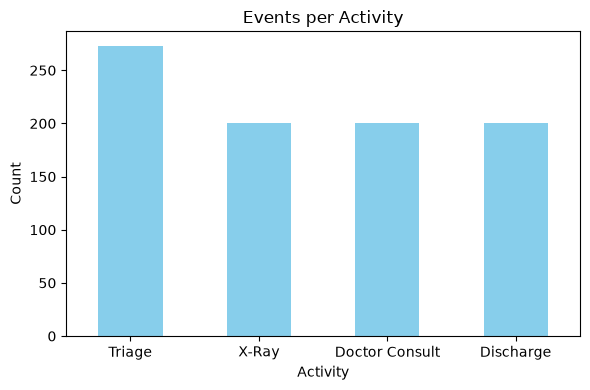

In [13]:
import matplotlib.pyplot as plt

activity_counts.plot(kind="bar", color="skyblue", figsize=(6,4))
plt.title("Events per Activity")
plt.xlabel("Activity")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Week 2 Prep: PM4Py Setup Test

In [4]:
import pm4py
print(pm4py.__version__)

2.7.23.4


In [5]:
import pandas as pd

# Load cleaned event log
log_df = pd.read_csv("../data/hospital_event_log_clean.csv")
log_df["Timestamp"] = pd.to_datetime(log_df["Timestamp"])

# Rename columns to PM4Py's expected format
log_df = log_df.rename(columns={
    "Case_ID": "case:concept:name",
    "Activity_Name": "concept:name",
    "Timestamp": "time:timestamp"
})

# Convert to PM4Py event log format
event_log = pm4py.convert_to_event_log(log_df)

print(f"Number of cases (patients): {len(event_log)}")
print("PM4Py event log created successfully!")

Number of cases (patients): 200
PM4Py event log created successfully!


In [2]:
import pandas as pd

# Load cleaned event log
df = pd.read_csv("../data/hospital_event_log_clean.csv")
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

# Calculate transition times between consecutive activities per patient
transition_times = []

for patient_id, group in df.groupby("Case_ID"):
    sorted_group = group.sort_values("Timestamp").reset_index(drop=True)
    for i in range(len(sorted_group) - 1):
        from_activity = sorted_group.loc[i, "Activity_Name"]
        to_activity = sorted_group.loc[i+1, "Activity_Name"]
        duration = (sorted_group.loc[i+1, "Timestamp"] - sorted_group.loc[i, "Timestamp"]).total_seconds() / 60
        transition_times.append({
            "from": from_activity,
            "to": to_activity,
            "duration_minutes": duration
        })

transitions_df = pd.DataFrame(transition_times)

# Average duration per transition type
avg_transitions = transitions_df.groupby(["from", "to"])["duration_minutes"].mean().sort_values(ascending=False)
print("Average Transition Times (minutes):")
print(avg_transitions)

Average Transition Times (minutes):
from            to            
X-Ray           Triage            20.876712
Triage          Doctor Consult    14.671233
X-Ray           Doctor Consult    14.606299
Triage          X-Ray             12.010000
Doctor Consult  Discharge          9.820000
Name: duration_minutes, dtype: float64
